In [203]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt

In [204]:
df = pd.read_csv("/home/havin-benoy/Desktop/Pyspiders/ml/Datasets/Ice_cream selling data.csv")
df.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [205]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(2)
memory usage: 916.0 bytes


In [206]:
x = df[["Temperature (°C)"]]        #2d
y = df["Ice Cream Sales (units)"]   #1d

In [207]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

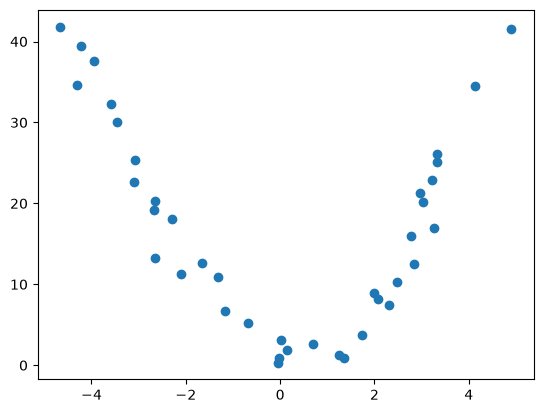

In [208]:
# Checking the linearity status of the data
plt.scatter(x_train,y_train)

In [209]:
display(df.corr())

,Temperature (°C),Ice Cream Sales (units)
Temperature (°C),1.000000,-0.175184
Ice Cream Sales (units),-0.175184,1.000000


### Note:
- This dataset is non linear in nature.
- it represents the a curve and we can use polynomial regression as pre-processing technique for making the linear regression learn this pattern.

In [210]:
poly = PolynomialFeatures(degree=2)

## Note:
- with the help of polynomial features we are going to tranform x_train and x_test with degree = 2
- here we have two methods:

    1. fit_transform():
        - it learns the pattern first and then transform the values

        - syntax:
            x_train = poly.fit_transform(x_train)

        - How fit_transform() works in polynomial features..?
            - fit() : learns the pattern (i.e decides how many features needs to be created based on degree)
            - transform(): transforms (calculates) the values for the created features
            - after fit_transform() information regarding the newly added features are stored in the object 'poly'
    
    2. transform():
        - It transforms the values directly with the help of poly (the object which is already having the information on which are the features that already got created. )


In [211]:
x_train_poly = poly.fit_transform(x_train)

# here x_train should only have numerical values

print(x_train_poly)

[[ 1.00000000e+00 -2.11186969e+00  4.45999359e+00]
 [ 1.00000000e+00 -3.57855372e+00  1.28060467e+01]
 [ 1.00000000e+00  2.31859124e+00  5.37586534e+00]
 [ 1.00000000e+00 -2.67246083e+00  7.14204687e+00]
 [ 1.00000000e+00 -3.94966109e+00  1.55998227e+01]
 [ 1.00000000e+00 -3.10844012e+00  9.66239999e+00]
 [ 1.00000000e+00  3.21136614e+00  1.03128725e+01]
 [ 1.00000000e+00  3.27004407e+00  1.06931882e+01]
 [ 1.00000000e+00  4.13086796e+00  1.70640701e+01]
 [ 1.00000000e+00 -1.32637898e+00  1.75928121e+00]
 [ 1.00000000e+00 -2.65228679e+00  7.03462523e+00]
 [ 1.00000000e+00 -1.17312327e+00  1.37621820e+00]
 [ 1.00000000e+00  6.88780908e-01  4.74419139e-01]
 [ 1.00000000e+00  2.07510060e+00  4.30604249e+00]
 [ 1.00000000e+00  1.74000001e+00  3.02760004e+00]
 [ 1.00000000e+00 -4.66226268e+00  2.17366933e+01]
 [ 1.00000000e+00  3.33593241e+00  1.11284451e+01]
 [ 1.00000000e+00  1.99931037e+00  3.99724195e+00]
 [ 1.00000000e+00 -3.45571170e+00  1.19419433e+01]
 [ 1.00000000e+00  1.35981267e+

## Note
- We can see 3 columns are here
- the first column is simply 1 (it is the weights of the intercept values :) )
- The second column is the actual values of the x_train
- The third column is the squared values of the x_train because the degree is 2

In [212]:
x_test_poly = poly.transform(x_test)
x_test_poly

array([[ 1.        , -1.81893761,  3.30853403],
       [ 1.        ,  3.70405744, 13.72004151],
       [ 1.        ,  4.13353379, 17.08610158],
       [ 1.        ,  3.61077848, 13.03772121],
       [ 1.        , -0.77333004,  0.59803936],
       [ 1.        ,  1.02418081,  1.04894634],
       [ 1.        ,  0.87490503,  0.76545881],
       [ 1.        ,  0.69359887,  0.4810794 ],
       [ 1.        ,  1.85055193,  3.42454243],
       [ 1.        , -0.14963487,  0.02239059]])

In [213]:
# Model Training
model = LinearRegression()
model.fit(x_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0. ,-0.71, 1.87]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.768
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[38.94,17.19, 0. ]"


In [214]:
'''
score() and r2_score() are both same 

general syntax:
    model.score(x,y)

train r2_score:
    model.score(x_train,y_train)

test r2_score:
    model.score(x_test,y_test)
'''

'\nscore() and r2_score() are both same \n\ngeneral syntax:\n    model.score(x,y)\n\ntrain r2_score:\n    model.score(x_train,y_train)\n\ntest r2_score:\n    model.score(x_test,y_test)\n'

### How does the score() calculates r2 score without we passing predicted output values
- first the model must be trained on (x_train,y_train) via using fit()
- then when we call the score(x_train,y_train), it will internally generate the predicted outputs of the model (y_train_pred) and use the (y_train,y_train_pred) to calculate the r2 score.

In [215]:
train_r2_score = model.score(x_train_poly,y_train)

test_r2_score = model.score(x_test_poly,y_test)

print(f"Train r2 score : {train_r2_score}\nTest r2 score : {test_r2_score}")

Train r2 score : 0.9413665676490518
Test r2 score : 0.843055137193884


### Conclusion

- Train Data:

    - Linear Regression captures the non linear data patterns with the help of polynomial features.
    - Model captures 94% of the seen data (train data) pattern. Therefore we can say that the model learned the pattern properly.

- Test Data:

    - model captures 84% of unseen data pattern , so it is ready for future predictions.
    - Model can perform well on unseen data (new data for future predictions).


### Degree comparison:

1. Degree = 2:

    Train r2 score : 0.9413665676490518
    Test r2 score : 0.843055137193884

2. Degree = 3:

    Train r2 score : 0.9469116778215552
    Test r2 score : 0.8405107685716909

3. Degree = 4:

    Train r2 score : 0.9590068634754769
    Test r2 score : 0.8054468908427672

## Conclusion:

- Degree 2 is best for the best performance of the model.
    

In [216]:
y_train_pred = model.predict(x_train_poly)
y_test_pred = model.predict(x_test_poly)

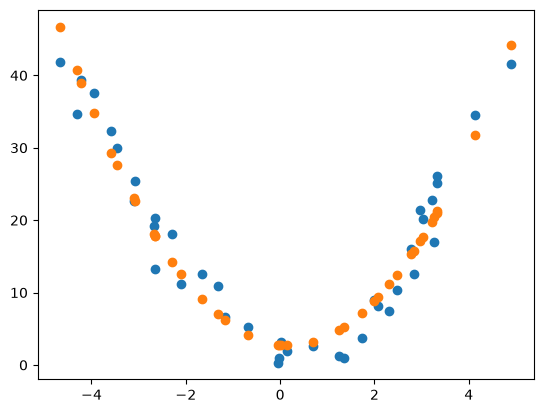

In [217]:
plt.scatter(x_train,y_train)
plt.scatter(x_train, y_train_pred)

# Try this for degree =1 , degree = 2 , degree = 3

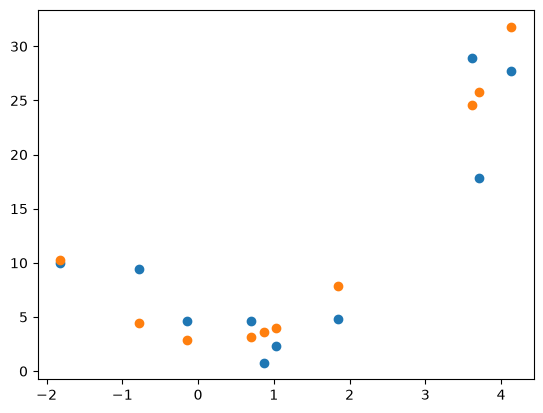

In [ ]:
plt.scatter(x_test,y_test)
plt.scatter(x_test, y_test_pred)

# Try this for degree =1 , degree = 2 , degree = 3
# In test data the samples are very less that is why it is not showing the a good pattern